# 14. EP3: solución en dos pasos y página (F6 y F7)

La solución final tiene **tres capas**: (1) el **filtro 1**, el detector de huecos por cámara; (2) el **modelo o regla** que ordena las cajas de las celdas sanas; (3) la **persona que revisa y decide**.

**Brazos comparados (plan v3, P4).** A: un paso, todas las cajas ordenadas. B: solo celdas sanas (sensibilidad). C: dos pasos, la Lista A se atiende aparte (sus positivos cuentan como hallados por la auditoría) y la Lista B ordena las cajas sanas. **No inventamos un costo por auditoría**: reportamos el costo en cajas con el que C empata con A (punto de equilibrio).

**Analogía.** Antes de revisar factura por factura, miramos si falta una carpeta completa de facturas de un mes; esa carpeta se pide una sola vez y no se revisa factura por factura.

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists()), Path("C:/Users/maico/waymo-evaluacion"))
sys.path.insert(0, str(RAIZ / "src"))
REP, IMG, APP = RAIZ / "data/08_reporting_ep3", RAIZ / "images/ep3", RAIZ / "data/09_app_ep3"
IMG.mkdir(parents=True, exist_ok=True)
RECALCULAR = False          # True: vuelve a correr los scripts de esta fase (puede tardar mucho; escribe solo en *_ep3)
SEMILLA = 42
EN_MUESTRA = "en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos"
GANANCIA_C = "La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco."
AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

from waymo_evaluacion.ep3.plan import verificar_plan_v3
print("Plan v3 verificado (sha256):", ", ".join(verificar_plan_v3(RAIZ)))


def coma(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def miles(x):
    return f"{int(round(x)):,}".replace(",", ".")


def guardar_fig(fig, nombre):
    fig.savefig(IMG / f"{nombre}.png", dpi=130, bbox_inches="tight")


def correr(script, *args):
    r = subprocess.run([sys.executable, "-X", "utf8", str(RAIZ / "scripts/ep3" / script), *args], capture_output=True, text=True, cwd=RAIZ)
    print(r.stdout[-1500:], r.stderr[-800:])
    assert r.returncode == 0, f"{script} fallo"

Plan v3 verificado (sha256): plan_v3.md, plan_v3.json


In [2]:
if RECALCULAR:
    correr("f7_preparar_app.py")
sel = json.loads((REP / "f6_seleccion.json").read_text(encoding="utf-8"))
elegido = sel["elegido"]
bc = pd.read_csv(REP / "f5_brazoC.csv").set_index("candidato")
bb = pd.read_csv(REP / "f5_brazoB.csv").set_index("candidato")
fila = bc.loc[elegido]
display(Markdown("**" + EN_MUESTRA + ". " + GANANCIA_C + "**"))
display(pd.DataFrame({"brazo": ["A (un paso)", "C (dos pasos)"], "Fracción de cajas para 80 % de recall": [fila["Fraccion_80_A"], fila["Fraccion_80_C"]],
                      "Captura al revisar 20 %": [fila["Captura@20_A"], fila["Captura@20_C"]]}).round(3))
display(Markdown(f"**Punto de equilibrio.** Dos pasos empata con un paso si cada auditoría de celda cuesta **{fila['equilibrio_cajas_por_auditoria']:.0f} cajas** "
                 f"(IC 95 % por segmentos {fila['equilibrio_lo']:.0f} a {fila['equilibrio_hi']:.0f}; {int(fila['celdas_auditadas'])} celdas auditadas). "
                 f"Los positivos que cubre la auditoría son {miles(int(fila['positivos_cubiertos_por_auditoria']))}. Si una auditoría cuesta menos que eso en tiempo de revisión, el flujo en dos pasos saldría a cuenta ({EN_MUESTRA}). {GANANCIA_C}"))
print("Brazo B (solo celdas sanas):", bb.loc[elegido, ["AUC", "PR-AUC", "Captura@20", "Fraccion_80"]].round(3).to_dict())

**en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos. La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco.**

,brazo,Fracción de cajas para 80 % de recall,Captura al revisar 20 %
0,A (un paso),0.446,0.619
1,C (dos pasos),0.296,0.709


**Punto de equilibrio.** Dos pasos empata con un paso si cada auditoría de celda cuesta **6059 cajas** (IC 95 % por segmentos 1227 a 13258; 2 celdas auditadas). Los positivos que cubre la auditoría son 1.565. Si una auditoría cuesta menos que eso en tiempo de revisión, el flujo en dos pasos saldría a cuenta (en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos). La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco.

Brazo B (solo celdas sanas): {'AUC': 0.879, 'PR-AUC': 0.711, 'Captura@20': 0.673, 'Fraccion_80': 0.337}


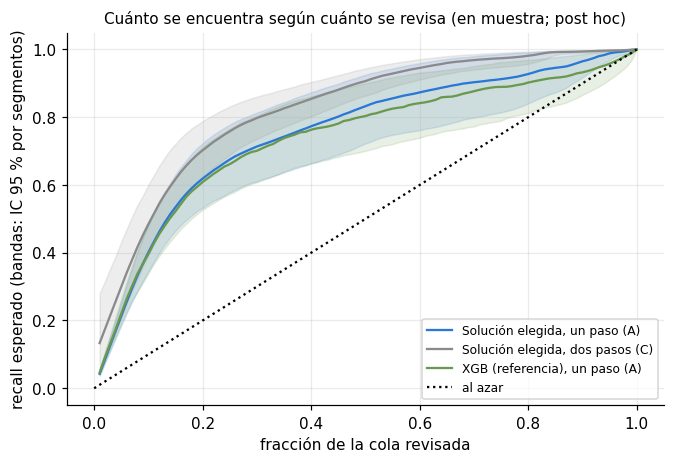

In [3]:
cur = pd.read_csv(APP / "curva_cola.csv")
fig, ax = plt.subplots(figsize=(7, 4.4))
for nombre, col in zip(cur["solucion"].unique(), (AZUL, GRIS, VERDE)):
    d = cur[cur["solucion"] == nombre]
    ax.plot(d["presupuesto"], d["recall"], color=col, label=nombre); ax.fill_between(d["presupuesto"], d["lo"], d["hi"], color=col, alpha=0.15)
ax.plot([0, 1], [0, 1], "k:", label="al azar")
ax.set_xlabel("fracción de la cola revisada"); ax.set_ylabel("recall esperado (bandas: IC 95 % por segmentos)"); ax.legend(fontsize=8); ax.set_title("Cuánto se encuentra según cuánto se revisa (en muestra; post hoc)", fontsize=10)
guardar_fig(fig, "14_curva_recall_presupuesto"); plt.show()

## Inferencia con la solución congelada (v3) sobre un segmento
Es una **demostración sobre un segmento de desarrollo** (no es una prueba ciega: el modelo final se entrenó con los 41 segmentos). Muestra cómo se obtienen las listas A y B desde `lidar_box` y la asociación.

In [4]:
from waymo_evaluacion.ep3.inferencia import cargar_artefactos, puntuar_segmento
art = cargar_artefactos(RAIZ / "data/06_models_ep3")
seg = "2577669988012459365_1640_000_1660_000"
lb = pd.read_parquet(RAIZ / f"data/01_raw/waymo/lidar_box/{seg}.parquet")
asoc = pd.read_parquet(RAIZ / f"data/01_raw/waymo/camera_to_lidar_box_association/{seg}.parquet")
r = puntuar_segmento(lb, asoc, art)
print(json.dumps(r.resumen, ensure_ascii=False, indent=1))
display(r.lista_A.round(3))
display(r.lista_B.drop(columns=["key.frame_timestamp_micros", "key.laser_object_id"]).head(5).round(3))

{
 "cajas_vru_poblacion_principal": 6474,
 "cajas_en_celdas_con_hueco": 1677,
 "cajas_en_lista_B": 4797,
 "celdas_con_hueco": 1,
 "tiene_asociacion": true,
 "umbral_A": -32.0,
 "umbral_B": -11.0,
 "positivos_total": 2046,
 "positivos_en_celdas_con_hueco": 1338
}


,segmento,camara,tasa,mediana_referencia,umbral,cajas_en_rango,cajas_afectadas
0,257766998801,3 (frontal der.),0.0,0.917,0.229,1677,1677


,segment_id,seg,object_type,azimut_abs_deg,distancia_m,num_lidar_points,num_top_lidar_points,score,prob_calibrada,en_hueco,posicion_en_cola,percentil_en_cola,sin_camara
6,2577669988012459365_1640_000_1660_000,257766998801,PEDESTRIAN,11.949,55.201,0,0,-0.0,0.852,False,1.0,0.000,1
41,2577669988012459365_1640_000_1660_000,257766998801,PEDESTRIAN,12.094,54.743,0,0,-0.0,0.852,False,2.0,0.000,1
77,2577669988012459365_1640_000_1660_000,257766998801,PEDESTRIAN,12.247,54.287,0,0,-0.0,0.852,False,3.0,0.001,1
112,2577669988012459365_1640_000_1660_000,257766998801,PEDESTRIAN,12.402,53.834,0,0,-0.0,0.852,False,4.0,0.001,1
147,2577669988012459365_1640_000_1660_000,257766998801,PEDESTRIAN,12.554,53.383,0,0,-0.0,0.852,False,5.0,0.001,1


## La página «Auditor de etiquetas 3D» (Streamlit) y su prueba de humo
Se ejecuta con `streamlit run app/app.py` (solo local). Aquí corremos **todas las secciones con cada perfil** con `streamlit.testing.v1.AppTest` sobre los datos reales de `data/09_app_ep3` para comprobar que no hay errores. El número de secciones y de perfiles se lee del código de la página.

In [5]:
import logging
logging.getLogger("streamlit").setLevel(logging.ERROR)
from streamlit.testing.v1 import AppTest
from waymo_evaluacion.ep3.app_logica import PERFILES, SECCIONES
estado = {}
for perfil in PERFILES:
    for s in SECCIONES:
        at = AppTest.from_file(str(RAIZ / "app/app.py"), default_timeout=120).run()
        at.sidebar.selectbox[0].set_value(perfil).run()
        at.sidebar.radio[0].set_value(s).run()
        estado.setdefault(s, {})[perfil] = "sin errores" if not at.exception else f"ERROR: {at.exception[0].value[:80]}"
display(pd.DataFrame(estado).T)
print(f"{len(SECCIONES)} secciones x {len(PERFILES)} perfiles = {len(SECCIONES) * len(PERFILES)} combinaciones; con error: {sum(v != 'sin errores' for d in estado.values() for v in d.values())}")

2026-11-15 08:01:39.197 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-15 08:01:41.536 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-15 08:01:42.079 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-15 08:01:42.656 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-15 08:01:43.345 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-15 08:01:44.045 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


... (16 outputs left out)

2026-11-15 08:01:53.419 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-15 08:01:53.903 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,Analista de revisión,Responsable de calidad de datos,Ingeniero consumidor de datos
Inicio,sin errores,sin errores,sin errores
Auditoría de cámaras,sin errores,sin errores,sin errores
Cola de revisión,sin errores,sin errores,sin errores
Explica una caja,sin errores,sin errores,sin errores
Evidencia,sin errores,sin errores,sin errores
Ética y límites,sin errores,sin errores,sin errores
Puntuar datos nuevos,sin errores,sin errores,sin errores
Ayuda y glosario,sin errores,sin errores,sin errores


8 secciones x 3 perfiles = 24 combinaciones; con error: 0


### Cifras de la página: antes y después del rediseño (F18-C)
El rediseño cambia el diseño y el lenguaje, no las cifras. La única diferencia deliberada es la **cobertura de la cola**: antes la tarjeta usaba la curva interpolada y el texto el conteo observado (70,2 % contra 70,3 %; 96,5 % contra 96,6 %); ahora hay una sola fuente (el conteo observado). Fuente: `pagina_comparacion_antes_despues.csv` y tiempos en `pagina_tiempos_carga.json` (AppTest, caché caliente, meta menor a 3 s).

In [6]:
comp = pd.read_csv(REP / "pagina_comparacion_antes_despues.csv")
display(comp[["seccion", "caso", "cifra", "antes", "despues"]])
tiempos = json.loads((REP / "pagina_tiempos_carga.json").read_text(encoding="utf-8"))
display(pd.DataFrame(tiempos["secciones"]).T)

,seccion,caso,cifra,antes,despues
0,Cola de revisión,presupuesto 20 %,cajas a revisar,15.726,15.726
1,Cola de revisión,presupuesto 20 %,horas (20 s por caja),"87,4","87,4"
2,Cola de revisión,presupuesto 20 %,cobertura (tarjeta antes / frase ahora),"70,2 %",70 de cada 100
3,Cola de revisión,presupuesto 20 %,filas de la tabla,500,500
4,Cola de revisión,presupuesto 68 %,cajas a revisar,53.466,53.466
5,Cola de revisión,presupuesto 68 %,horas (20 s por caja),"297,0","297,0"
6,Cola de revisión,presupuesto 68 %,cobertura (tarjeta antes / frase ahora),"96,5 %",97 de cada 100
7,Cola de revisión,presupuesto 68 %,filas de la tabla,500,500
8,Inicio,resultados técnicos,AUC fuera de fold,"0,823","0,823"
9,Inicio,resultados técnicos,Recall en el punto A,"79,8 %","79,8 %"


,primera_s,mejor_s,cumple_meta
Inicio,0.42,0.42,True
Auditoría de cámaras,0.54,0.45,True
Cola de revisión,0.54,0.5,True
Explica una caja,0.45,0.45,True
Evidencia,0.53,0.53,True
Ética y límites,0.53,0.45,True
Puntuar datos nuevos,0.47,0.44,True
Ayuda y glosario,0.48,0.45,True


## Validación externa sellada (P9) y despliegue
- Los segmentos nuevos **todavía no existen**. `notebooks/00b_seleccion_segmentos_ep3.ipynb` (para Colab) reconstruye la selección de EP2 y toma segmentos nunca evaluados.
- Antes de abrirlos: `scripts/ep3/evaluar_sellado.py congelar` guarda el sha256 de la lista y de los modelos; después `evaluar` corre **una sola vez** (candado) y compara solución elegida contra regla, dos pasos contra un paso; del detector se medirá la tasa de celdas marcadas y su estabilidad (sin verdad externa, DEV-3). Nada se selecciona con esos datos.
- Despliegue: local (`scripts/ep3/arrancar_app.bat`) y Docker (`docker compose up --build`, datos como volumen de solo lectura). Docker **no se probó** (Docker Desktop apagado). La guía de AWS (EC2 + S3 privado) es solo orientativa y advierte que los datos por caja de Waymo no deben salir del equipo. Ver `docs/ep3/despliegue.md`.